Best Flight Path (x, y):
[[ 0.    0.  ]
 [ 0.    0.  ]
 [ 0.    0.  ]
 [ 0.    0.  ]
 [ 0.94  0.  ]
 [ 6.96  4.42]
 [10.   10.  ]]

Best Fitness Value: 14.76
Total Flight Distance: 14.76
Obstacle Intersections: 0
Result: Collision-free path found in this model.


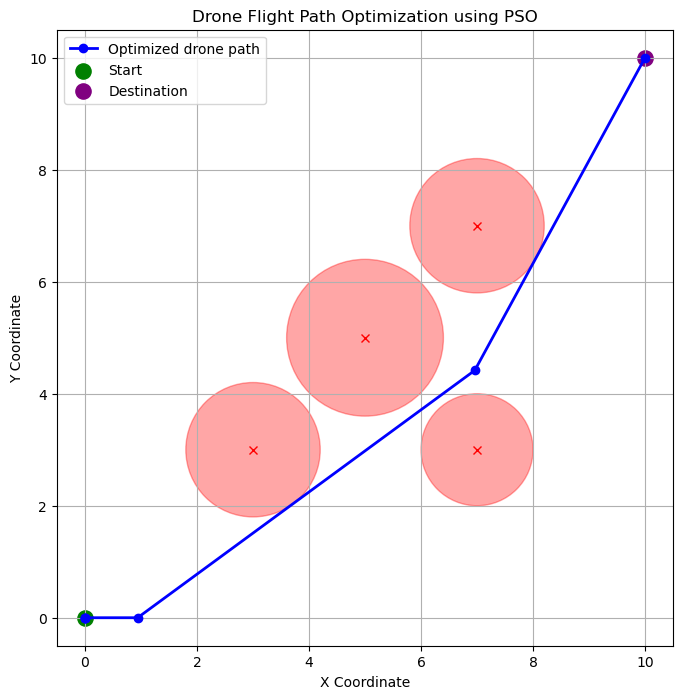

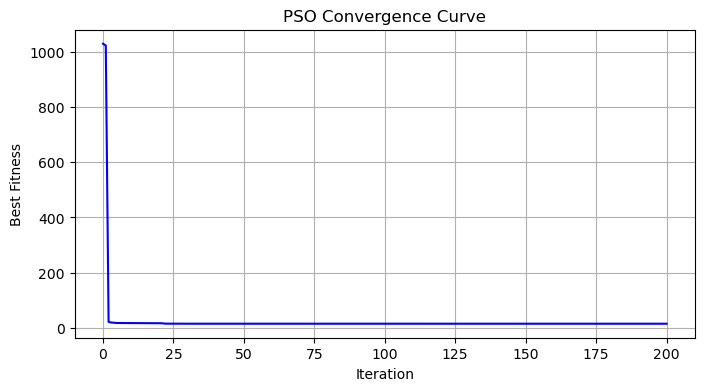

In [1]:

import numpy as np
import matplotlib.pyplot as plt
start = np.array([0.0, 0.0])
goal = np.array([10.0, 10.0])
obstacles = [
    (3.0, 3.0, 1.2),
    (5.0, 5.0, 1.4),
    (7.0, 7.0, 1.2),
    (7.0, 3.0, 1.0)
]
n_waypoints = 5
N = 40                 
T = 200                
w = 0.7                
c1 = 1.5               
c2 = 1.5              
lower_bound = 0.0
upper_bound = 10.0
collision_penalty = 1000.0
np.random.seed(42)
positions = np.random.uniform(
    lower_bound, upper_bound, (N, n_waypoints, 2)
)
velocities = np.random.uniform(
    -1.0, 1.0, (N, n_waypoints, 2)
)
def distance(p1, p2):
    return np.linalg.norm(p2 - p1)
def segment_hits_obstacle(p1, p2, obstacle):
    ox, oy, radius = obstacle
    center = np.array([ox, oy])
    segment = p2 - p1
    length_squared = np.dot(segment, segment)
    if length_squared == 0:
        closest = p1
    else:
        t = np.dot(center - p1, segment) / length_squared
        t = np.clip(t, 0.0, 1.0)
        closest = p1 + t * segment
    return distance(closest, center) <= radius
def fitness(path):
    full_path = np.vstack([start, path, goal])
    total_distance = sum(
        distance(full_path[i], full_path[i + 1])
        for i in range(len(full_path) - 1)
    )
    collisions = 0
    for i in range(len(full_path) - 1):
        for obstacle in obstacles:
            if segment_hits_obstacle(
                full_path[i], full_path[i + 1], obstacle
            ):
                collisions += 1
    return total_distance + collision_penalty * collisions
pbest_positions = positions.copy()
pbest_scores = np.array([
    fitness(p) for p in positions
])
best_index = np.argmin(pbest_scores)
gbest_position = pbest_positions[best_index].copy()
gbest_score = pbest_scores[best_index]
history = [gbest_score]
for iteration in range(T):
    for i in range(N):
        r1 = np.random.random((n_waypoints, 2))
        r2 = np.random.random((n_waypoints, 2))
        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest_positions[i] - positions[i])
            + c2 * r2 * (gbest_position - positions[i])
        )
        positions[i] = positions[i] + velocities[i]
        positions[i] = np.clip(
            positions[i], lower_bound, upper_bound
        )
        current_score = fitness(positions[i])
        if current_score < pbest_scores[i]:
            pbest_scores[i] = current_score
            pbest_positions[i] = positions[i].copy()
    best_index = np.argmin(pbest_scores)
    if pbest_scores[best_index] < gbest_score:
        gbest_score = pbest_scores[best_index]
        gbest_position = pbest_positions[best_index].copy()
    history.append(gbest_score)
best_path = np.vstack([start, gbest_position, goal])
collision_count = sum(
    segment_hits_obstacle(best_path[i], best_path[i + 1], obstacle)
    for i in range(len(best_path) - 1)
    for obstacle in obstacles
)
print("Best Flight Path (x, y):")
print(np.round(best_path, 2))
print("\nBest Fitness Value:", round(gbest_score, 2))
print("Total Flight Distance:",
      round(sum(distance(best_path[i], best_path[i + 1])
                for i in range(len(best_path) - 1)), 2))
print("Obstacle Intersections:", collision_count)
if collision_count == 0:
    print("Result: Collision-free path found in this model.")
else:
    print("Result: No collision-free path found yet. Try more iterations.")
fig, ax = plt.subplots(figsize=(8, 8))
for ox, oy, radius in obstacles:
    circle = plt.Circle(
        (ox, oy), radius,
        color="red", alpha=0.35
    )
    ax.add_patch(circle)
    ax.plot(ox, oy, "rx")
ax.plot(
    best_path[:, 0], best_path[:, 1],
    "b-o", linewidth=2, markersize=6,
    label="Optimized drone path"
)
ax.scatter(*start, color="green", s=120, label="Start")
ax.scatter(*goal, color="purple", s=120, label="Destination")
ax.set_xlim(-0.5, 10.5)
ax.set_ylim(-0.5, 10.5)
ax.set_xlabel("X Coordinate")
ax.set_ylabel("Y Coordinate")
ax.set_title("Drone Flight Path Optimization using PSO")
ax.grid(True)
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()
plt.figure(figsize=(8, 4))
plt.plot(history, color="blue")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence Curve")
plt.grid(True)
plt.show()
